# Diagnose a Clifford proxy for magic-state preparation

Flag post-selection can trade preparation yield for a lower error rate among accepted states.
Here we examine that tradeoff in a Clifford circuit obtained by replacing non-Clifford rotations in a proposed Steane-code magic-state preparation.
We call this modified circuit a Clifford proxy: it can be simulated by Stim, a Clifford-circuit simulator, but prepares a different state and propagates faults differently from the original protocol.
The proxy therefore lets us study its own acceptance rule without claiming results for the non-Clifford protocol.
We discard attempts whose flag detectors fire and compare retained-shot logical failure with the fraction of attempts discarded.

The [state-preparation notebook](../5_state_preparation.ipynb) introduces the diagnostics and explains their ideal final readout.
This example defines its circuit and sampling configuration independently.

## Setup

Run the next cell once in a fresh notebook environment.
IPython's `%pip` magic installs into the active kernel, so the following imports use the same environment.

In [1]:
%%capture
%pip install qldpc matplotlib

In [2]:
from collections.abc import Sequence

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import sinter
import stim
from matplotlib.figure import Figure

from qldpc import circuits, codes, decoders

NUM_WORKERS = 1

## Sampling and plotting

We use a single physical error parameter for depolarizing noise on active gates and for incorrect reset states and measurement outcomes.
Idle noise is disabled, and final diagnostic measurements are noiseless.
Logical failure is the fraction of retained shots with an incorrectly predicted logical-observable flip.
Discard rate is the fraction of all attempted shots rejected by the flag rule.
We collect samples with Sinter, Stim's sampling and decoding tool, and plot bands spanning rates within a factor of 1,000 of the maximum binomial likelihood.
A dotted line marks equality between the per-operation physical error parameter and the logical failure probability per retained preparation; these describe different units of work.

In [3]:
def plot_sinter_results(
    stats: Sequence[sinter.TaskStats],
) -> tuple[Figure, npt.NDArray[np.object_]]:
    """Plot logical error rates and any discard rates in Sinter statistics."""
    with_discards = any(stat.discards for stat in stats)
    if with_discards:
        figure, axes = plt.subplots(1, 2, sharex=True, figsize=(7.5, 3.2))
        error_axis, discard_axis = axes
    else:
        figure, error_axis = plt.subplots(figsize=(4.5, 3.2))
        axes = np.array([error_axis])

    grouped = sinter.group_by(stats, key=lambda stat: stat.json_metadata.get("label", ""))
    markers = ("o", "s", "^", "D")
    for index, (label, group_stats) in enumerate(sorted(grouped.items())):
        plot_args = {
            "color": f"C{index}",
            "marker": markers[index % len(markers)],
            "label": label or "state preparation",
        }
        sinter.plot_error_rate(
            ax=error_axis,
            stats=group_stats,
            x_func=lambda stat: stat.json_metadata["p"],
            plot_args_func=lambda _index, _curve_id, _group, args=plot_args: args,
        )
        if with_discards and any(stat.discards for stat in group_stats):
            sinter.plot_discard_rate(
                ax=discard_axis,
                stats=group_stats,
                x_func=lambda stat: stat.json_metadata["p"],
                plot_args_func=lambda _index, _curve_id, _group, args=plot_args: args,
            )

    physical_rates = sorted({stat.json_metadata["p"] for stat in stats})
    error_axis.plot(
        physical_rates,
        physical_rates,
        color="black",
        linestyle=":",
        label=r"$p_{\mathrm{logical}}=p_{\mathrm{physical}}$",
    )
    error_axis.set_ylabel("logical failure probability among retained shots")
    if with_discards:
        discard_axis.set_ylabel("estimated discard rate")

    for axis in axes:
        axis.set_xlabel("physical error rate per operation")
        axis.loglog()
        axis.grid(which="both", alpha=0.3)
        handles, labels = axis.get_legend_handles_labels()
        if handles:
            axis.legend(handles, labels, loc="best")
    figure.tight_layout()
    return figure, axes

In [4]:
code = codes.SteaneCode()
error_rates = np.logspace(-3, -1, 5)
noise_model_family = circuits.DepolarizingNoiseModel
sinter_decoder = decoders.SinterDecoder(decoder=decoders.lookup(max_weight=1))

## A Clifford proxy for magic-state preparation

Stim cannot simulate the non-Clifford circuit in Figure 3b of [arXiv:2603.04584v1](https://arxiv.org/abs/2603.04584v1) directly.
Replacing the indicated $\pi/4$ rotations with Clifford $\pi/2$ rotations gives a proxy that prepares $|+\rangle$ instead of $|H\rangle$.
Changing these rotations changes both the prepared state and fault propagation, so the estimates characterize the Clifford proxy rather than the original magic-state preparation circuit.

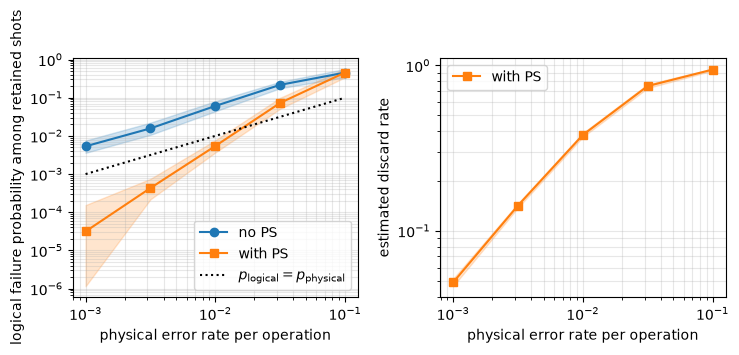

In [5]:
hadamard_prep_circuit = """
    H 1 2 3 7
    CX 1 0 3 5 7 6
    CX 1 4 2 6
    CX 2 0 1 5 3 6
    ########################################################
    TPP X1*X6  # "T-like" pi/4 rotation about a Pauli string
    ########################################################
    CX 7 6 6 4
    MX 7
    S_DAG 0 1 2 3 4 5 6  # logical S gate
    ##################################################################
    # logical stabilizer measurement
    H 8
    CX 8 9
    ###########################
    # controlled-Hadamard gates
    TPP_DAG Y0 Y1 Y2 Y3 Y4 Y5 Y6
    CZ 8 3 9 5
    CZ 8 0 9 2
    CZ 8 1 9 6
    CZ 8 4
    TPP Y0 Y1 Y2 Y3 Y4 Y5 Y6
    ###########################
    CX 8 9
    MX 8
    MZ 9
    ##################################################################
    # code stabilizer measurements
    H 11
    CX 3 10 11 2
    CX 2 10 11 3
    CX 1 10 11 4
    CX 4 10 11 1
    MZ 10
    MX 11
"""
circuit = stim.Circuit(hadamard_prep_circuit.replace("TPP", "SPP"))

tasks = circuits.get_state_prep_diagnostic_tasks(
    code, circuit, error_rates, noise_model_family, metadata={"label": "no PS"}
)
tasks += circuits.get_state_prep_diagnostic_tasks(
    code,
    circuit,
    error_rates,
    noise_model_family,
    add_flags=True,
    post_select="flags",
    metadata={"label": "with PS"},
)

stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=100_000,
    max_errors=100,
)

plot_sinter_results(stats)
plt.show()

The two labelled curves use the same noisy proxy circuit with and without post-selection.
The discard panel shows how many attempts are rejected to obtain the conditional error rate in the post-selected curve.
Both panels concern the modified Clifford circuit, including its changed fault propagation.

## One physical error rate

For a targeted check, `get_state_prep_diagnostic_circuit` provides an assembled Stim circuit and `get_logical_error_and_discard_rate` returns estimates at a single physical error rate.

In [6]:
diagnostic_circuit, detector_record = circuits.get_state_prep_diagnostic_circuit(
    code, circuit, add_flags=True
)
noisy_diagnostic_circuit = noise_model_family(1e-3).noisy_circuit(diagnostic_circuit)
logical_error_rate, discard_rate = circuits.get_logical_error_and_discard_rate(
    noisy_diagnostic_circuit,
    sinter_decoder,
    num_samples=100_000,
    post_select=detector_record.get_events("flags"),
)
print(f"retained-shot logical failure estimate: {logical_error_rate:.4g}")
print(f"discard fraction: {discard_rate:.4g}")

retained-shot logical failure estimate: 8.409e-05
discard fraction: 0.04863
